In [1]:
#import libraries
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from preprocessing import load_adult, onehot, save_predictions, save_model
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

In [2]:
#loading the dataset
trainDf, testDf = load_adult()

print(trainDf.shape)
print(testDf.shape)

(32561, 15)
(16281, 15)


In [3]:
#preprocessing features and seperating labels
xTrain, xTest = onehot(trainDf, testDf)

yTrain = trainDf["income"]
yTest = testDf["income"]

print(xTrain.shape)
print(xTest.shape)

(32561, 108)
(16281, 108)


In [4]:
#training initial random forest model
rfModel = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rfModel.fit(xTrain, yTrain)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [5]:
#evaluating initial random forest model
yPred = rfModel.predict(xTest)

initialAccuracy = accuracy_score(yTest, yPred)

print("Random Forest Accuracy:", initialAccuracy)
print(classification_report(yTest, yPred))
print(confusion_matrix(yTest, yPred))

Random Forest Accuracy: 0.850991953811191
              precision    recall  f1-score   support

           0       0.88      0.93      0.90     12435
           1       0.72      0.61      0.66      3846

    accuracy                           0.85     16281
   macro avg       0.80      0.77      0.78     16281
weighted avg       0.85      0.85      0.85     16281

[[11507   928]
 [ 1498  2348]]


In [6]:
#setting up grid search and cross validation
paramGrid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [7]:
#grid search
grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    paramGrid,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1
)

grid.fit(xTrain, yTrain)

/home/ponziopilato/Universita/cosetre/overseas/machine/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ponziopilato/Universita/cosetre/overseas/machine/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/ponziopilato/Universita/cosetre/overseas/machine/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'min_samples_split': [2, 5], 'n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set a

In [8]:
#grid search results
trainAcc = grid.cv_results_["mean_train_score"][grid.best_index_]
valAcc = grid.best_score_

print("Best parameters:", grid.best_params_)
print(f"Training accuracy: {trainAcc:.1%}")
print(f"Validation accuracy: {valAcc:.1%}")

Best parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}
Training accuracy: 90.5%
Validation accuracy: 86.4%


In [9]:
#evaluating random forest model after  grid search and cross validation
yPredTuned = grid.predict(xTest)

testAcc = accuracy_score(yTest, yPredTuned)

print(f"Tuned Random Forest Test Accuracy: {testAcc:.1%}")

Tuned Random Forest Test Accuracy: 86.3%


In [10]:
#model result summary
results = pd.DataFrame({
    "Metric": [
        "Initial Test Accuracy",
        "Best Number of Trees",
        "Best Maximum Depth",
        "Best Minimum Samples to Split",
        "Training Accuracy",
        "Cross-Validation Accuracy",
        "Tuned Test Accuracy"
    ],
    "Result": [
        f"{initialAccuracy:.2%}",
        grid.best_params_["n_estimators"],
        grid.best_params_["max_depth"],
        grid.best_params_["min_samples_split"],
        f"{trainAcc:.2%}",
        f"{valAcc:.2%}",
        f"{testAcc:.2%}"
    ]
})

display(results)

,Metric,Result
0,Initial Test Accuracy,85.10%
1,Best Number of Trees,100
2,Best Maximum Depth,20
3,Best Minimum Samples to Split,5
4,Training Accuracy,90.50%
5,Cross-Validation Accuracy,86.44%
6,Tuned Test Accuracy,86.32%


In [11]:
#function to introduce label noise
def addLabelNoise(y, noiseLevel, randomState=42):
    rng = np.random.default_rng(randomState)
    yNoisy = y.to_numpy().copy()

    nFlip = int(len(yNoisy) * noiseLevel)
    flipIndices = rng.choice(len(yNoisy), size=nFlip, replace=False)

    yNoisy[flipIndices] = 1 - yNoisy[flipIndices]

    return yNoisy

In [12]:
#repeating noise experiments with different random seeds
noiseLevels = [0, 0.1, 0.2, 0.3, 0.4]
seeds = [0, 1, 2, 3, 4]
repeatedResults = []
runs = []
for noiseLevel in noiseLevels:
    for seed in seeds:
        yTrainNoisy = addLabelNoise(yTrain, noiseLevel, randomState=seed)

        model = RandomForestClassifier(
            **grid.best_params_,
            random_state=42,
            n_jobs=-1
        )

        model.fit(xTrain, yTrainNoisy)
        yPred = model.predict(xTest)
        runs.append((noiseLevel, seed, model.predict_proba(xTest)[:, 1]))
        if seed == 0: save_model("randomForest", noiseLevel, model)
        accuracy = accuracy_score(yTest, yPred)

        repeatedResults.append({
            "Noise Level": noiseLevel,
            "Seed": seed,
            "Accuracy": accuracy,
            "Error Rate": 1 - accuracy,
            "Precision": precision_score(yTest, yPred),
            "Recall": recall_score(yTest, yPred),
            "F1 Score": f1_score(yTest, yPred)
        })

repeatedDf = pd.DataFrame(repeatedResults)
save_predictions("randomForest", runs)
summaryDf = repeatedDf.groupby("Noise Level")[
    ["Accuracy", "Error Rate", "Precision", "Recall", "F1 Score"]
].agg(["mean", "std"])

display(summaryDf)


Accuracy           Error Rate           Precision            \
                 mean       std       mean       std      mean       std   
Noise Level                                                                
0.0          0.863153  0.000000   0.136847  0.000000  0.777055  0.000000   
0.1          0.862760  0.000856   0.137240  0.000856  0.771756  0.002378   
0.2          0.858878  0.000868   0.141122  0.000868  0.755924  0.002795   
0.3          0.852048  0.002237   0.147952  0.002237  0.737657  0.007775   
0.4          0.818586  0.006607   0.181414  0.006607  0.637537  0.021121   

               Recall            F1 Score            
                 mean       std      mean       std  
Noise Level                                          
0.0          0.589964  0.000000  0.670706  0.000000  
0.1          0.595008  0.003302  0.671949  0.002439  
0.2          0.594592  0.002748  0.665617  0.002167  
0.3          0.580031  0.005116  0.649396  0.004764  
0.4          0.540094  0.016377  0.584470  0.011099

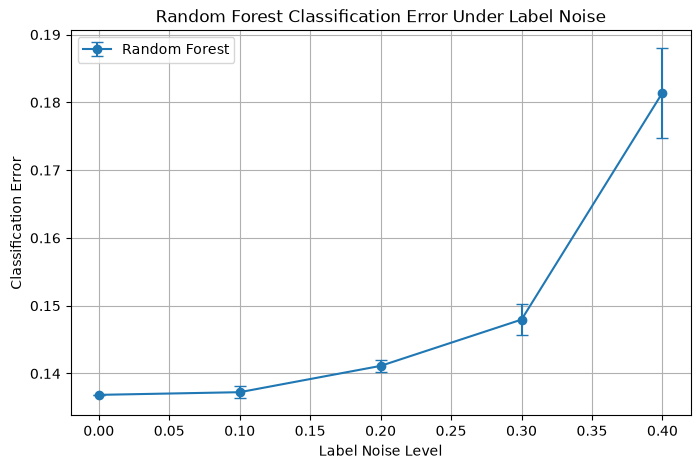

In [13]:
#plotting mean classification error against label noise
meanError = summaryDf["Error Rate"]["mean"]
stdError = summaryDf["Error Rate"]["std"]

plt.figure(figsize=(8, 5))

plt.errorbar(
    noiseLevels,
    meanError,
    yerr=stdError,
    marker="o",
    capsize=4,
    label="Random Forest"
)

plt.xlabel("Label Noise Level")
plt.ylabel("Classification Error")
plt.title("Random Forest Classification Error Under Label Noise")
plt.legend()
plt.grid(True)
plt.show()